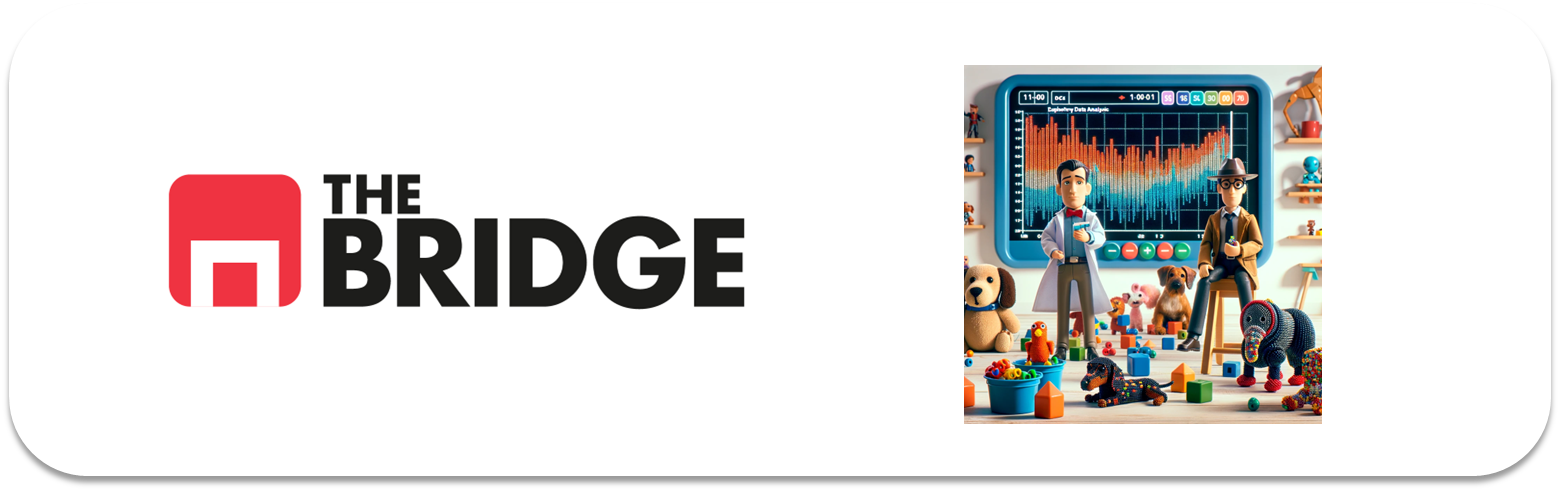

## Análisis de Datos (Multivariante): Todo numéricas

Supongamos que por el desarrollo y necesidades del análisis de datos tenemos que cotejar varias variables numéricas a la vez. Además de las posibles visualizaciones que pueda recomendarte el interesante [sitio](https://www.data-to-viz.com) que ya hemos mencionado otras veces, yo te propongo como punto de partida (luego tendrás que completarlo tú) lo siguiente que viene a continuación en el notebook.

Como tónica habitual de este sprint, cargamos, importamos, arrancamos:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from bootcampviztools import plot_categorical_numerical_relationship, plot_combined_graphs, \
    pinta_distribucion_categoricas, plot_grouped_boxplots, plot_categorical_relationship_fin, plot_grouped_histograms, \
        grafico_dispersion_con_correlacion, bubble_plot

df_seguros = pd.read_csv("../data/Marketing-Customer-Analysis.csv")

### Seguros: CLV - prima mensual - importe reclamado - ingresos

Lo primero sería mostrar los valores y diagramas de cada uno así como las correlaciones dos a dos:

(3, 2)


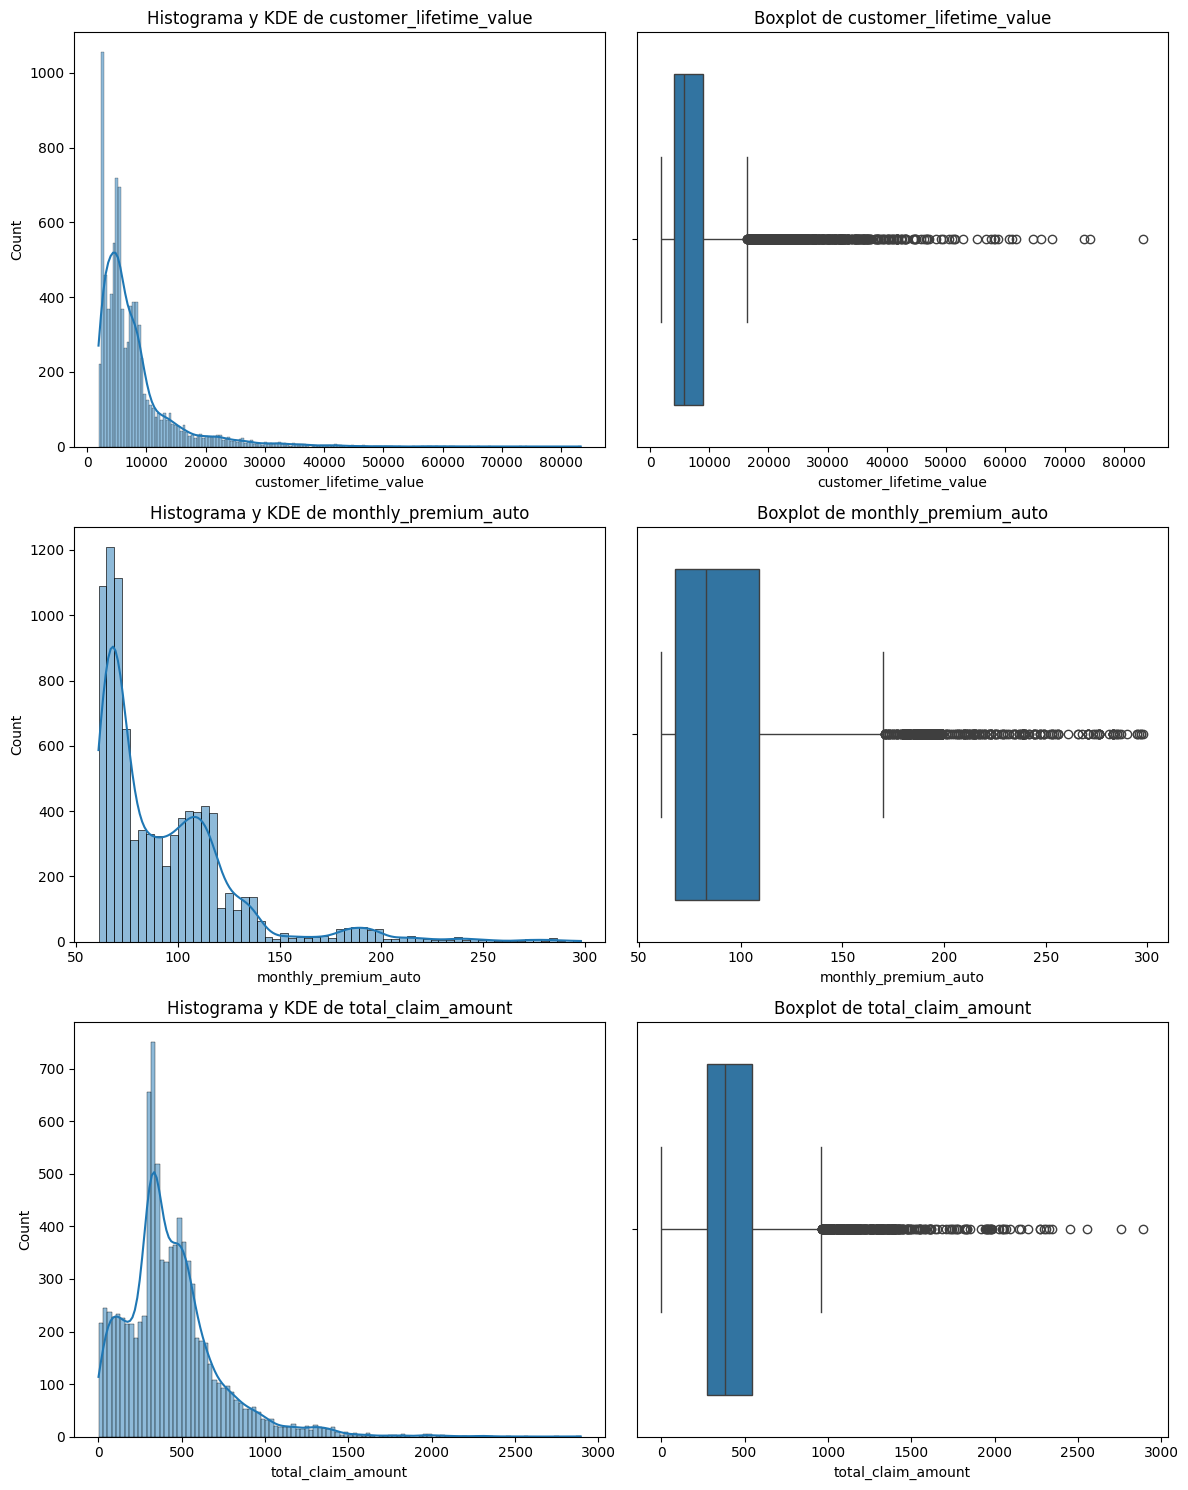

In [2]:
plot_combined_graphs(df_seguros, ["customer_lifetime_value", "monthly_premium_auto", "total_claim_amount"])

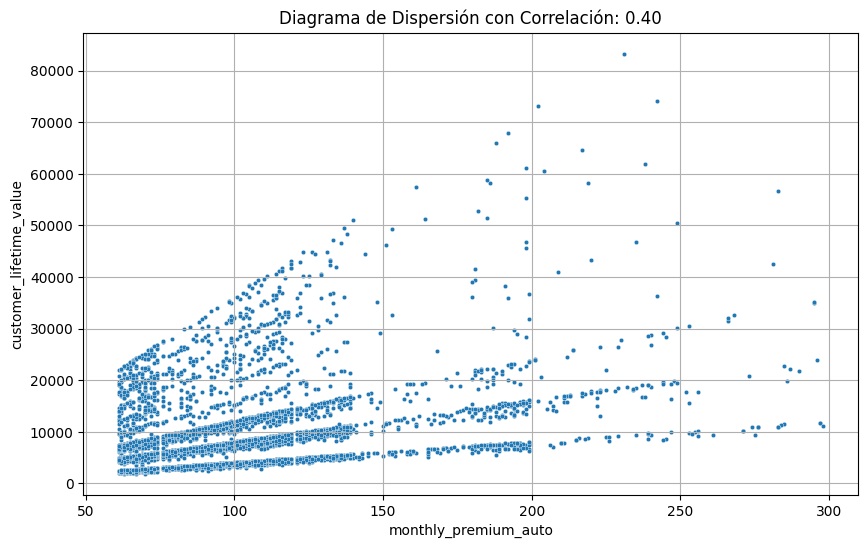

In [3]:
grafico_dispersion_con_correlacion(df_seguros, "monthly_premium_auto", "customer_lifetime_value", mostrar_correlacion=True, tamano_puntos=10)

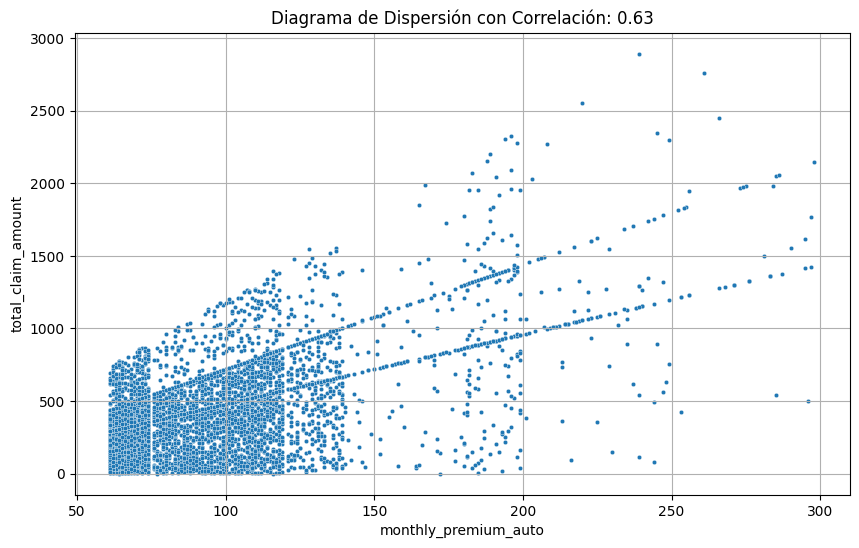

In [4]:
grafico_dispersion_con_correlacion(df_seguros, "monthly_premium_auto", "total_claim_amount", mostrar_correlacion=True, tamano_puntos=10)

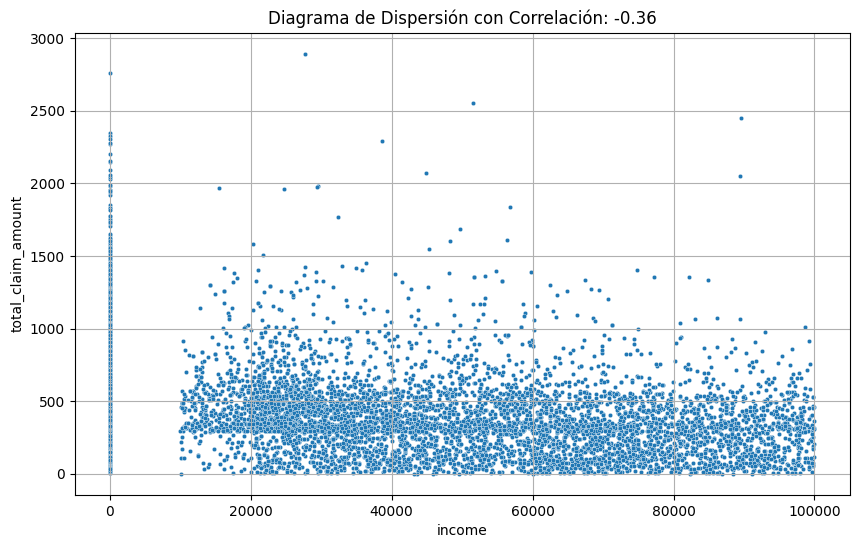

In [5]:
grafico_dispersion_con_correlacion(df_seguros, "income", "total_claim_amount", mostrar_correlacion=True, tamano_puntos=10)

Lo siguiente será mostrar los tres valores a la vez, con un diagrama de burbujas que es como un scatter plot (un diagrama de dispersión) pero en el que el tamaño de los puntos los marca la tercera variable:

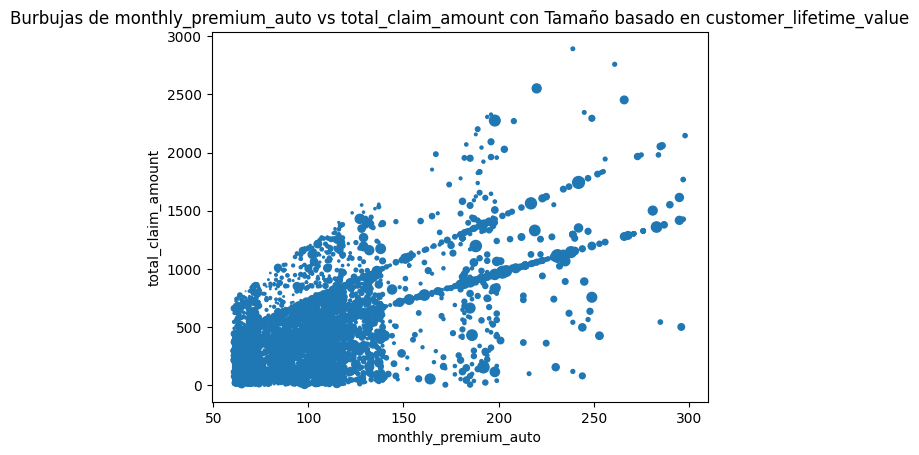

In [6]:
bubble_plot(df_seguros, "monthly_premium_auto", "total_claim_amount", "customer_lifetime_value", scale=1000)

El tamaño de las burbujas es el CLV. Varias cosas a apuntar:
* La prima mensual y el importe reclamado van claramente de la mano (correlación ≈ 0,63): a más prima, más se reclama.
* Las burbujas grandes (CLV alto) no se concentran solo en las primas altas: el CLV depende de algo más que la prima (en el notebook anterior vimos que, sobre todo, del número de pólizas).
* En el gráfico de ingresos frente a reclamación aparece una franja vertical en income = 0: los parados, que reclaman más en mediana. Buena parte de la correlación negativa entre ingresos y reclamación (≈ -0,36) viene de ese grupo.

El siguiente paso sería convertir una de las variables en categórica (como hicimos con `number_of_policies`) y estaríamos en el análisis multivariante del notebook anterior.

### Analisis multivariante: Matriz de correlación

Para terminar, pandas permite obtener la matriz de correlación de sus variables numéricas. Es decir una matriz en la que aparecen las correlaciones (de pearson, si no se indica lo contrario) dos a dos:

In [7]:
corr_matrix = df_seguros.corr(numeric_only= True) # Si no lo pones y tienes variables tipo texto, fallará7
corr_matrix

,customer_lifetime_value,income,monthly_premium_auto,months_since_last_claim,months_since_policy_inception,number_of_open_complaints,number_of_policies,total_claim_amount
customer_lifetime_value,1.000000,0.024366,0.396262,0.011517,0.009418,-0.036343,0.021955,0.226451
income,0.024366,1.000000,-0.016665,-0.026715,-0.000875,0.006408,-0.008656,-0.355254
monthly_premium_auto,0.396262,-0.016665,1.000000,0.005026,0.020257,-0.013122,-0.011233,0.632017
months_since_last_claim,0.011517,-0.026715,0.005026,1.000000,-0.042959,0.005354,0.009136,0.007563
months_since_policy_inception,0.009418,-0.000875,0.020257,-0.042959,1.000000,-0.001158,-0.013333,0.003335
number_of_open_complaints,-0.036343,0.006408,-0.013122,0.005354,-0.001158,1.000000,0.001498,-0.014241
number_of_policies,0.021955,-0.008656,-0.011233,0.009136,-0.013333,0.001498,1.000000,-0.002354
total_claim_amount,0.226451,-0.355254,0.632017,0.007563,0.003335,-0.014241,-0.002354,1.000000


Y aún hay más, con seaborn podemos hacer una representación de esta matriz a través de lo que se denomina un "mapa de calor":

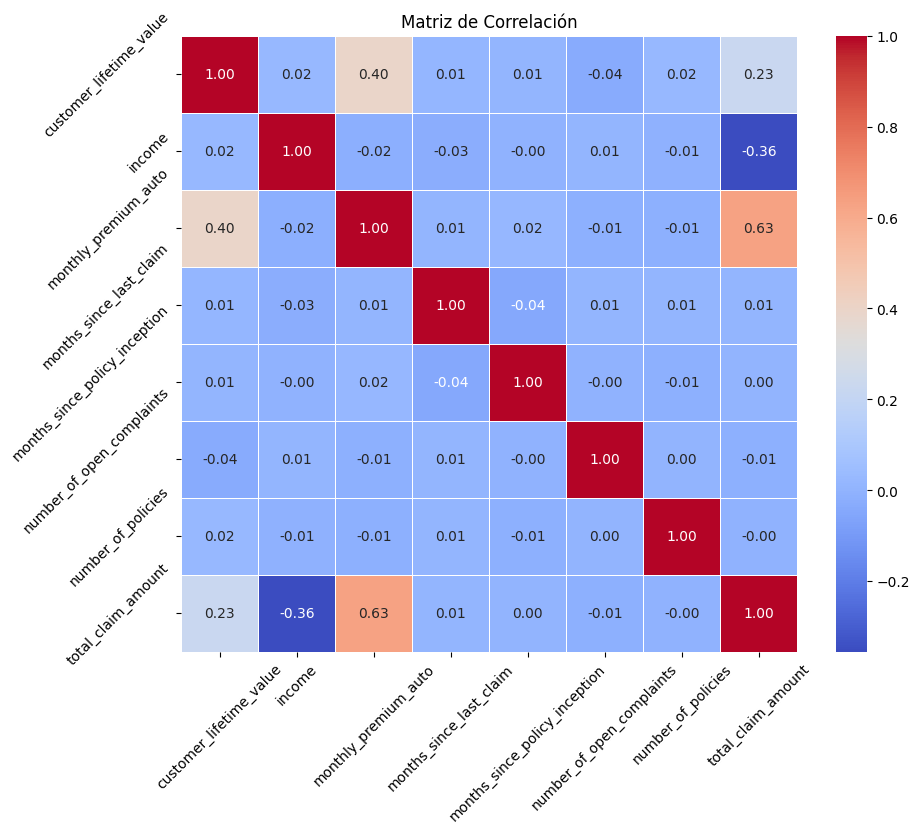

In [8]:
plt.figure(figsize=(10, 8))  # Ya lo veremos pero esto permite ajustar el tamaño de las gráficas
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", 
            cbar=True, square=True, linewidths=.5) # el cmap es el rango de colores usado para representar "el calor"

plt.title('Matriz de Correlación')
plt.xticks(rotation=45)  # Rota las etiquetas de las x si es necesario
plt.yticks(rotation=45)  # Rota las etiquetas de las y si es necesario

plt.show()


Y para terminar también es posible completar tu análisis bivariante/multivariante con una visualización de los diagramas de dispersión (pero ojo que si son muchos no verás nada)

In [9]:
df_solo_numeros = df_seguros[["customer_lifetime_value", "monthly_premium_auto", "total_claim_amount", "income"]]
df_solo_numeros.columns

Index(['customer_lifetime_value', 'monthly_premium_auto', 'total_claim_amount',
       'income'],
      dtype='str')

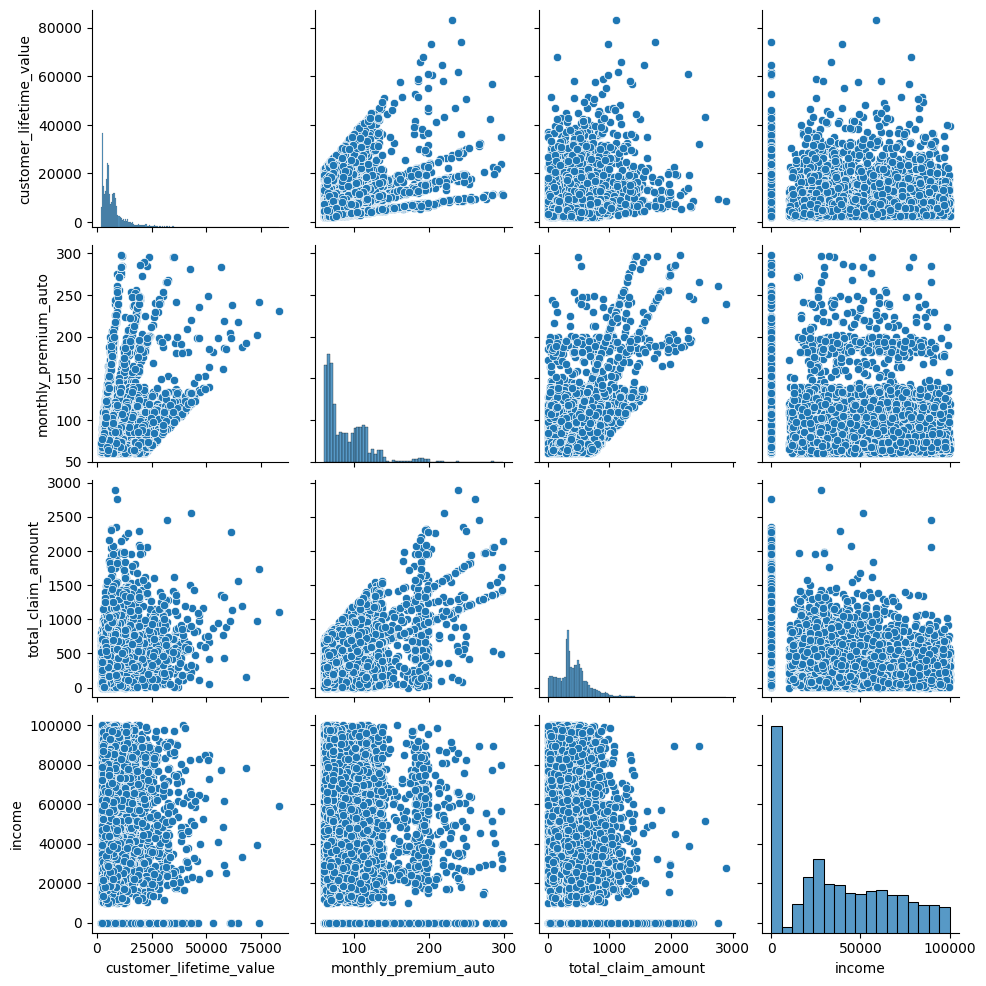

In [10]:
sns.pairplot(df_solo_numeros)
plt.show()

### Análisis de datos: (humilde) guía de referencia del EDA

**PARTE I: Preparación** (`U01/01`)
1. **Establecer objetivos**
2. **Completar la definición de los datos**: ficha del dataset y tabla de variables
3. **Tipificar los datos** y echar un primer vistazo a su calidad (nulos, duplicados, tipos)
4. **Priorizar variables**: directoras (target) y de agrupación

**PARTE II: Análisis univariante** (`U01/02` a `U01/08`)

5. **Frecuencias de las categóricas**: gráficos de barras
6. **Tendencia central**: media, mediana, moda
7. **Posición y rangos de las numéricas**: diagramas de caja
8. **Dispersión**: desviación estándar y coeficiente de variación
9. **Forma y distribución**: histogramas, densidad, asimetría y curtosis
10. **Outliers**: detéctalos (2-3 desviaciones estándar si la distribución parece normal; si no, bigotes de 3 veces el IQR) y decide qué hacer con ellos **en el análisis** (mantener, separar). Su tratamiento (eliminar, capar...) es parte de Data Cleaning.

**PARTE III: Análisis bivariante** (`U02/01` a `U02/06`)

11. **Revisa prioridades, preguntas y notas** hasta el momento
12. **Empieza por las variables directoras**: categórica-categórica, categórica-numérica y numérica-numérica (gráficos y medidas)
13. **¿Real o casualidad?**: aplica el test adecuado y reporta siempre también el tamaño de la diferencia o de la correlación
14. **Visión rápida de todas las numéricas**: matriz de correlación, heatmap y pairplot
15. **Recapitula**: clasifica tus hallazgos en posibles mensajes, elementos a profundizar y cosas interesantes pero no importantes (descártalas). Apunta las preguntas contestadas y las pendientes.

**PARTE IV: Análisis multivariante** (`U02/07` y `U02/08`)

16. **Intenta resolver las preguntas pendientes**
17. **Si necesitas 3 o más variables**, planifica muy bien qué grupos: una categórica como directora y bivariantes por cada valor, o burbujas y matrices para numéricas
18. **Acaba el análisis**: cierra las preguntas pendientes; lo que quede por trabajar son líneas de trabajo futuro.